# Introduction to CLASS (`classy`) and Cobaya

This notebook walks through the two tools step by step:

1. **CLASS** – a Boltzmann solver. Given cosmological parameters it computes the expansion history,
   thermal history, perturbations and finally observables such as the CMB power spectra $C_\ell$ and the matter power spectrum $P(k)$.
   `classy` is its Python wrapper.
2. **Cobaya** – a framework for Bayesian inference. It connects a *theory code* (here CLASS) with *likelihoods*
   and a *sampler* (e.g. MCMC) to obtain posterior distributions of parameters.

Run the cells top to bottom. Kernel: the `Code/.venv` environment.

## 0. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from classy import Class          # Python wrapper of CLASS
import cobaya
print("cobaya version:", cobaya.__version__)

cobaya version: 3.6.2


# Part 1 — CLASS

### 1.1 Create an instance and set parameters

- `Class()` creates an (empty) CLASS object.
- `.set(dict)` passes input parameters, using the **same names as in CLASS `.ini` files** (see `explanatory.ini` in `class_public`).
- `output` tells CLASS *what* to compute: `tCl` (temperature), `pCl` (polarisation), `lCl` (lensing potential), `mPk` (matter power spectrum).
- `lensing: yes` makes the lensed spectra available.

In [3]:
params = {
    # ΛCDM parameters (approx. Planck 2018)
    'omega_b':   0.02237,   # physical baryon density  Ω_b h²
    'omega_cdm': 0.1200,    # physical CDM density     Ω_c h²
    'h':         0.6736,    # H0 / (100 km/s/Mpc)
    'A_s':       2.1e-9,    # amplitude of primordial scalar spectrum
    'n_s':       0.9649,    # scalar spectral index
    'tau_reio':  0.0544,    # optical depth to reionisation
    # what to compute
    'output': 'tCl,pCl,lCl,mPk',
    'lensing': 'yes',
    'l_max_scalars': 2500,
    'P_k_max_1/Mpc': 3.0,   # max k for P(k)
    'z_max_pk': 2.0,        # max redshift for P(k)
}

cosmo = Class()
cosmo.set(params)

True

### 1.2 Run the computation

`.compute()` runs all CLASS modules in order: *background → thermodynamics → perturbations → primordial → fourier (non-linear) → transfer → harmonic → lensing*.
After this, the results can be queried.

In [4]:
%time cosmo.compute()

CPU times: user 2.79 s, sys: 165 ms, total: 2.95 s
Wall time: 408 ms


### 1.3 Derived / background quantities

Many quick getter functions exist. Units: distances in **Mpc**, $H(z)$ in **1/Mpc** (i.e. $H/c$).

In [ ]:
print("H0 [km/s/Mpc]     :", cosmo.Hubble(0) * 299792.458)   # Hubble(z) returns H/c in 1/Mpc
print("Omega_m           :", cosmo.Omega_m())
print("Omega_Lambda      :", cosmo.Omega_Lambda())
print("age [Gyr]         :", cosmo.age())
print("sigma8            :", cosmo.sigma8())
print("z_rec (decoupling):", cosmo.get_current_derived_parameters(['z_rec'])['z_rec'])
print("100*theta_s       :", cosmo.get_current_derived_parameters(['100*theta_s'])['100*theta_s'])

z = 1.0
print(f"\nAt z = {z}:")
print("  angular diameter distance D_A [Mpc]:", cosmo.angular_distance(z))
print("  luminosity distance D_L [Mpc]      :", cosmo.luminosity_distance(z))

H0 [km/s/Mpc]     : 67.36
Omega_m           : 0.31377210267376066
Omega_Lambda      : 0.6861357164699876
age [Gyr]         : 13.81403780839944
sigma8            : 0.8229075027438469
z_rec (decoupling): 1088.7786673464352
100*theta_s       : 1.0403737515023483

At z = 1.0:
  angular diameter distance D_A [Mpc]: 1702.6867767957522
  luminosity distance D_L [Mpc]      : 6810.747107183008


`get_background()` returns a dictionary with the full tabulated background evolution (all columns CLASS computed).

['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_lambda', '(.)rho_ur', '(.)rho_crit', '(.)rho_tot'] ...


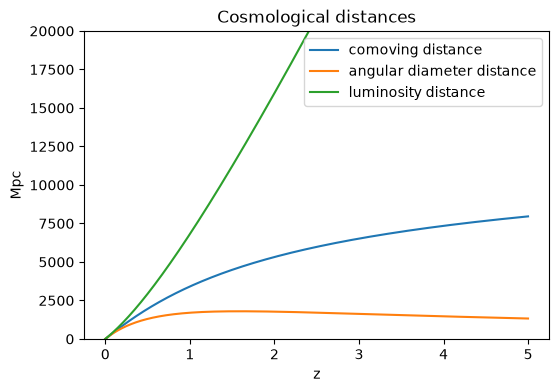

In [ ]:
bg = cosmo.get_background()
print(list(bg.keys())[:15], '...')

zb = bg['z']
mask = zb < 5
plt.figure(figsize=(6, 4))
plt.plot(zb[mask], bg['comov. dist.'][mask], label='comoving distance')
plt.plot(zb[mask], bg['ang.diam.dist.'][mask], label='angular diameter distance')
plt.plot(zb[mask], bg['lum. dist.'][mask], label='luminosity distance')
plt.xlabel('z'); plt.ylabel('Mpc'); plt.ylim(0, 2e4); plt.legend(); plt.title('Cosmological distances')
plt.show()

### 1.4 CMB power spectra

- `raw_cl(lmax)` → **unlensed** spectra, `lensed_cl(lmax)` → **lensed** spectra.
- Returned as a dict with keys `'ell', 'tt', 'ee', 'te', 'bb', 'pp', 'tp'`.
- Values are **dimensionless** $C_\ell$. To get the usual plot in $\mu K^2$ multiply by $\ell(\ell+1)/2\pi \times (T_{\rm cmb}\cdot 10^6)^2$.

dict_keys(['tt', 'ee', 'te', 'bb', 'pp', 'tp', 'ell'])


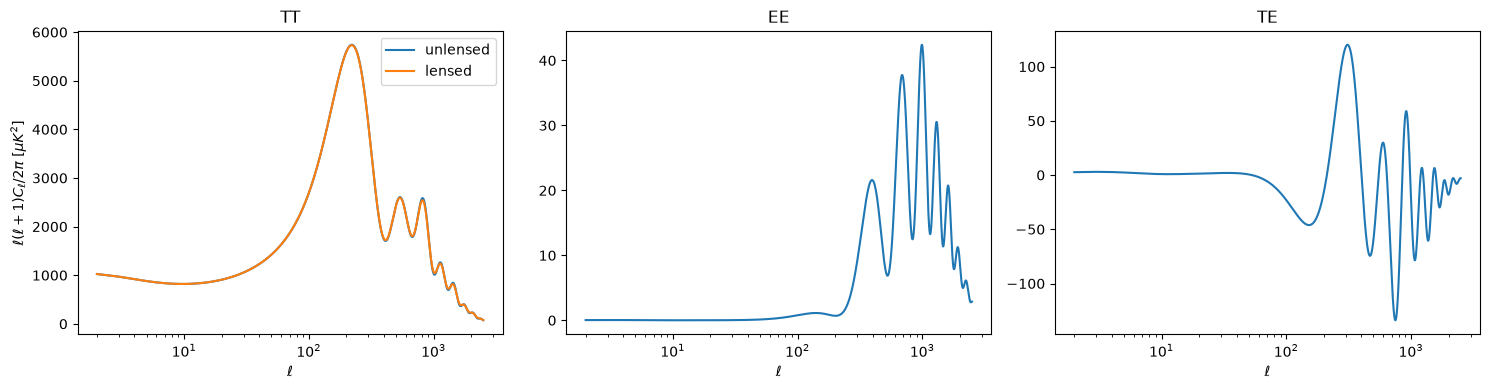

In [11]:
lmax = 2500
cl_lensed = cosmo.lensed_cl(lmax)
cl_raw    = cosmo.raw_cl(lmax)
print(cl_lensed.keys())

ell = cl_lensed['ell'][2:]
T_uK = cosmo.T_cmb() * 1e6
factor = ell * (ell + 1) / (2 * np.pi) * T_uK**2

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ell, factor * cl_raw['tt'][2:], label='unlensed')
ax[0].plot(ell, factor * cl_lensed['tt'][2:], label='lensed')
ax[0].set_title('TT'); ax[0].set_ylabel(r'$\ell(\ell+1)C_\ell/2\pi\ [\mu K^2]$')
ax[1].plot(ell, factor * cl_lensed['ee'][2:]); ax[1].set_title('EE')
ax[2].plot(ell, factor * cl_lensed['te'][2:]); ax[2].set_title('TE')
for a in ax: a.set_xlabel(r'$\ell$'); a.set_xscale('log')
ax[0].legend(); plt.tight_layout(); plt.show()

### 1.5 Matter power spectrum

`pk(k, z)` returns $P(k,z)$ in Mpc³ with $k$ in **1/Mpc** (not h/Mpc!). `pk_lin` gives the linear one.

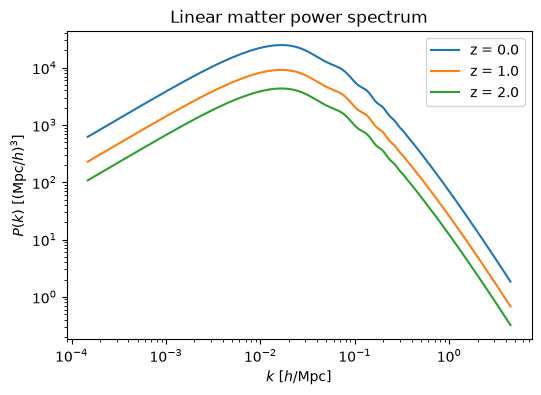

In [12]:
h = cosmo.h()
kk = np.logspace(-4, np.log10(3.0), 300)       # in 1/Mpc

plt.figure(figsize=(6, 4))
for zz in [0.0, 1.0, 2.0]:
    Pk = np.array([cosmo.pk_lin(k, zz) for k in kk])
    plt.loglog(kk / h, Pk * h**3, label=f'z = {zz}')   # convert to h/Mpc and (Mpc/h)^3
plt.xlabel(r'$k\ [h/{\rm Mpc}]$'); plt.ylabel(r'$P(k)\ [({\rm Mpc}/h)^3]$')
plt.legend(); plt.title('Linear matter power spectrum'); plt.show()

### 1.6 Changing a parameter

To recompute with new parameters: `.set()` new values and `.compute()` again.
`struct_cleanup()` frees CLASS's internal memory; `empty()` additionally resets all input parameters.
Here we vary $\omega_{\rm cdm}$ and see how the acoustic peaks change.

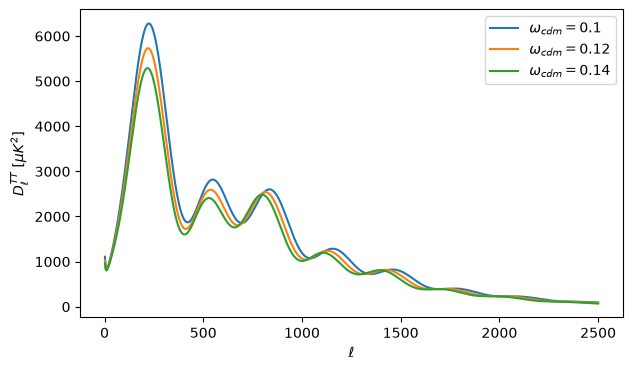

In [13]:
plt.figure(figsize=(7, 4))
for wc in [0.10, 0.12, 0.14]:
    c = Class()
    c.set(params)
    c.set({'omega_cdm': wc})
    c.compute()
    cl = c.lensed_cl(lmax)
    plt.plot(ell, factor * cl['tt'][2:], label=rf'$\omega_{{cdm}}={wc}$')
    c.struct_cleanup(); c.empty()
plt.xlabel(r'$\ell$'); plt.ylabel(r'$D_\ell^{TT}\ [\mu K^2]$'); plt.legend(); plt.show()

# Part 2 — Cobaya

Cobaya needs three ingredients, given as one dictionary (or a YAML file):

| block        | meaning |
|--------------|---------|
| `theory`     | the code computing observables (here `classy`) |
| `likelihood` | how probable the data are given the observables |
| `params`     | which parameters are **sampled** (have a `prior`), **fixed** (a number) or **derived** |
| `sampler`    | algorithm used to explore the posterior (`evaluate`, `mcmc`, `polychord`, …) |

To keep this notebook self‑contained (no Planck data download needed) we create a **toy likelihood**:
mock TT data generated from our fiducial cosmology, with cosmic-variance errors.

### 2.1 A toy likelihood

A Gaussian likelihood for a full-sky, noiseless TT spectrum (cosmic variance only):

$$-2\ln\mathcal{L} = \sum_\ell (2\ell+1)\left[\frac{\hat C_\ell}{C_\ell} + \ln C_\ell - \frac{2\ell -1}{2\ell+1}\ln \hat C_\ell\right] + \text{const}$$

Simplified here to a Gaussian $\chi^2$ with $\sigma_\ell = \sqrt{2/(2\ell+1)}\,C_\ell$.

In cobaya a likelihood can be a plain Python function. The argument `_self` gives access to
`_self.provider`, from which we fetch the theory products we declared under `requires`.

In [ ]:
LMAX_LIKE = 1500

# mock data = lensed TT from the fiducial CLASS run above, in muK^2 (cobaya returns muK^2 by default)
cl_data = cl_lensed['tt'][:LMAX_LIKE + 1] * T_uK**2
ells = np.arange(LMAX_LIKE + 1)
sigma = np.sqrt(2.0 / (2 * ells + 1)) * cl_data

def toy_tt_loglike(_self=None):
    """Return log-likelihood of mock TT data given the current theory."""
    cl_theory = _self.provider.get_Cl(ell_factor=False, units='muK2')['tt'][:LMAX_LIKE + 1]
    chi2 = np.sum(((cl_theory[2:] - cl_data[2:]) / sigma[2:])**2)
    return -0.5 * chi2

### 2.2 The input dictionary

- Sampled parameters get a `prior` (here uniform: `min`/`max`), a starting point `ref`, a `proposal` width and a LaTeX label.
- Fixed parameters are just numbers.
- Derived parameters (like `sigma8`, `Omega_m`) are requested with an empty dict / `latex` entry — CLASS computes them for free.
- `extra_args` are passed directly to CLASS (`.set()`).

In [ ]:
info = {
    'theory': {
        'classy': {
            'extra_args': {'lensing': 'yes', 'non_linear': 'none'},
        }
    },
    'likelihood': {
        'toy_tt': {
            'external': toy_tt_loglike,
            'requires': {'Cl': {'tt': LMAX_LIKE}},   # tells cobaya which products CLASS must compute
        }
    },
    'params': {
        # sampled
        'omega_cdm': {'prior': {'min': 0.10, 'max': 0.14},
                      'ref': 0.12, 'proposal': 0.0003, 'latex': r'\omega_{\rm cdm}'},
        'n_s':       {'prior': {'min': 0.90, 'max': 1.02},
                      'ref': 0.965, 'proposal': 0.002, 'latex': r'n_s'},
        # fixed
        'omega_b':  0.02237,
        'h':        0.6736,
        'A_s':      2.1e-9,
        'tau_reio': 0.0544,
        # derived
        'sigma8':   {'latex': r'\sigma_8'},
        'Omega_m':  {'latex': r'\Omega_m'},
    },
}

### 2.3 `get_model`: evaluate the posterior at a point

`get_model(info)` builds the pipeline without running a sampler. Useful to test that everything works
and to understand what cobaya computes.

- `model.logposterior(point)` → returns log-prior, log-likelihoods and derived parameters.
- `model.prior` / `model.parameterization` let you inspect the parameter setup.

In [ ]:
from cobaya.model import get_model

model = get_model(info)

print("Sampled params:", list(model.parameterization.sampled_params()))
print("Derived params:", list(model.parameterization.derived_params()))

point = {'omega_cdm': 0.12, 'n_s': 0.9649}
res = model.logposterior(point)
print("\nlog-posterior :", res.logpost)
print("log-prior     :", res.logprior)
print("log-likelihood:", res.loglikes)
print("derived       :", dict(zip(model.parameterization.derived_params(), res.derived)))

Scan the log-likelihood along one parameter to see that it peaks at the fiducial value:

In [ ]:
wcs = np.linspace(0.115, 0.125, 11)
logL = [model.loglike({'omega_cdm': w, 'n_s': 0.9649}, return_derived=False) for w in wcs]

plt.figure(figsize=(6, 4))
plt.plot(wcs, logL, 'o-'); plt.axvline(0.12, color='k', ls='--', label='fiducial')
plt.xlabel(r'$\omega_{\rm cdm}$'); plt.ylabel(r'$\ln\mathcal{L}$'); plt.legend(); plt.show()

### 2.4 Running an MCMC

Add a `sampler` block and call `run(info)`. It returns the updated info and the sampler object;
`sampler.products()['sample']` holds the chain.

We use very loose convergence settings so it finishes in a few minutes (each CLASS call takes ~0.25 s) — for real work let it converge
(`Rminus1_stop ≈ 0.01`) and run several chains with MPI (`mpirun -n 4 cobaya-run input.yaml`).

In [ ]:
from cobaya.run import run

info['sampler'] = {'mcmc': {'max_samples': 300, 'Rminus1_stop': 0.1, 'learn_proposal': True}}
info['output'] = None        # set e.g. 'chains/toy' to write chains to disk
info['force'] = True

updated_info, sampler = run(info)

### 2.5 Analysing the chain with GetDist

`sampler.products()['sample']` is a cobaya `SampleCollection`; `.to_getdist()` converts it so we can
compute means / constraints and make triangle plots.

In [ ]:
from getdist import plots

samples = sampler.products()['sample']
gd = samples.to_getdist()
print(gd.getTable(limit=1).tableTex())

g = plots.get_subplot_plotter()
g.triangle_plot(gd, ['omega_cdm', 'n_s', 'sigma8', 'Omega_m'], filled=True,
                markers={'omega_cdm': 0.12, 'n_s': 0.9649})
plt.show()

# Next steps

- Replace the toy likelihood with real ones, e.g. `planck_2018_lowl.TT`, `planck_2018_highl_plik.TTTEEE_lite`
  or the SPT/ACT `candl` likelihoods (`cobaya-install` downloads data).
- Put the `info` dictionary into a YAML file and run from the terminal with `cobaya-run file.yaml`.
- Useful references: CLASS `explanatory.ini` (all input parameters), `classy` source `python/classy.pyx`
  (all Python methods), and the cobaya docs: https://cobaya.readthedocs.io